In [ ]:
%matplotlib inline
import math
import numpy as np
import torch
from matplotlib import pyplot as plt
from matplotlib_inline import backend_inline

In [ ]:
def use_svg_display():
    """Use the svg format to display a plot in Jupyter."""
    backend_inline.set_matplotlib_formats('svg')

def set_figsize(figsize=(3.5, 2.5)):
    """Set the figure size for matplotlib."""
    use_svg_display()
    plt.rcParams['figure.figsize'] = figsize

In [ ]:
def plot(X, Y=None, xLabel=None, yLabel=None, legend=[], xlim=None, ylim=None, xscale='linear', yscale='linear', fmts=('-', 'm--', 'g-.', 'r:'), figsize=(3.5,2.5), axes=None):
    """Plot data points"""
    def has_one_axis(X):
        return (hasattr(X, "ndim") and X.ndim == 1 or isinstance(X,list) and not hasattr(X[0], "__len__"))

    if has_one_axis(X): X=[X]
    if Y is None:
        X,Y = [[]]*len(X), X
    elif has_one_axis(Y):
        Y=[Y]
    if len(X) != len(Y):
        X = X*len(Y)

    set_figsize(figsize)
    if axes is None:
        axes = plt.gca()
    axes.cla()
    for x,y,fmt in zip(X, Y, fmts):
        axes.plot(x,y,fmt) if len(x) else axes.plot(y,fmt)
    set_axes(axes, xLabel, yLabel, xlim, ylim, xscale, yscale, legend)

def set_axes(axes, xlabel, ylabel, xlim, ylim, xscale, yscale, legend):
    """set axis for matplotlib"""
    axes.set_xlabel(xlabel)
    axes.set_ylabel(ylabel)
    axes.set_xscale(xscale)
    axes.set_yscale(yscale)
    axes.set_xlim(xlim)
    axes.set_ylim(ylim)
    if legend:
        axes.legend(legend)
    axes.grid()

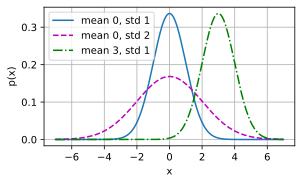

In [ ]:
def normal(x, mu, sigma):
    p=1/math.sqrt(2*math.pi*sigma**2)
    return p * np.exp(-0.5*(x-mu)**2/sigma**2)

x = np.arange(-7, 7, 0.01)

params = [(0,1), (0,2), (3,1)]
plot(x, [normal(x,mu,sigma) for mu,sigma in params], xLabel='x', yLabel='p(x)', figsize=(4.5, 2.5), legend=[f'mean {mu}, std {sigma}' for mu,sigma in params])